In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.formula.api as sm

In [53]:
train = pd.read_csv('./train_energy_data.csv')
train = pd.get_dummies(train, columns = ['Building Type', 'Day of Week'], drop_first = True, dtype = int)

test = pd.read_csv('./test_energy_data.csv')
test = pd.get_dummies(test, columns = ['Building Type', 'Day of Week'], drop_first = True, dtype = int)

train.head()

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Energy Consumption,Building Type_Industrial,Building Type_Residential,Day of Week_Weekend
0,7063,76,10,29.84,2713.95,0,1,0
1,44372,66,45,16.72,5744.99,0,0,0
2,19255,37,17,14.30,4101.24,1,0,1
3,13265,14,41,32.82,3009.14,0,1,0
4,13375,26,18,11.92,3279.17,0,0,0


<Axes: >

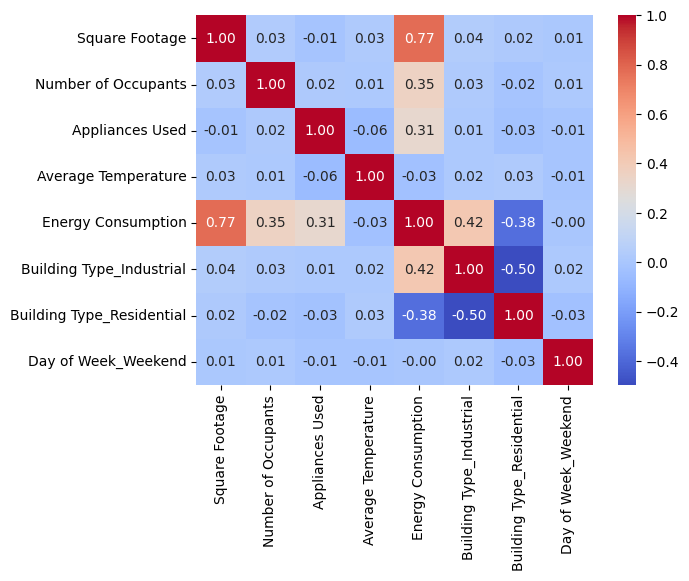

In [54]:
correlation = train.corr()

sns.heatmap(correlation, cmap = 'coolwarm', annot = True, fmt = '.2f')

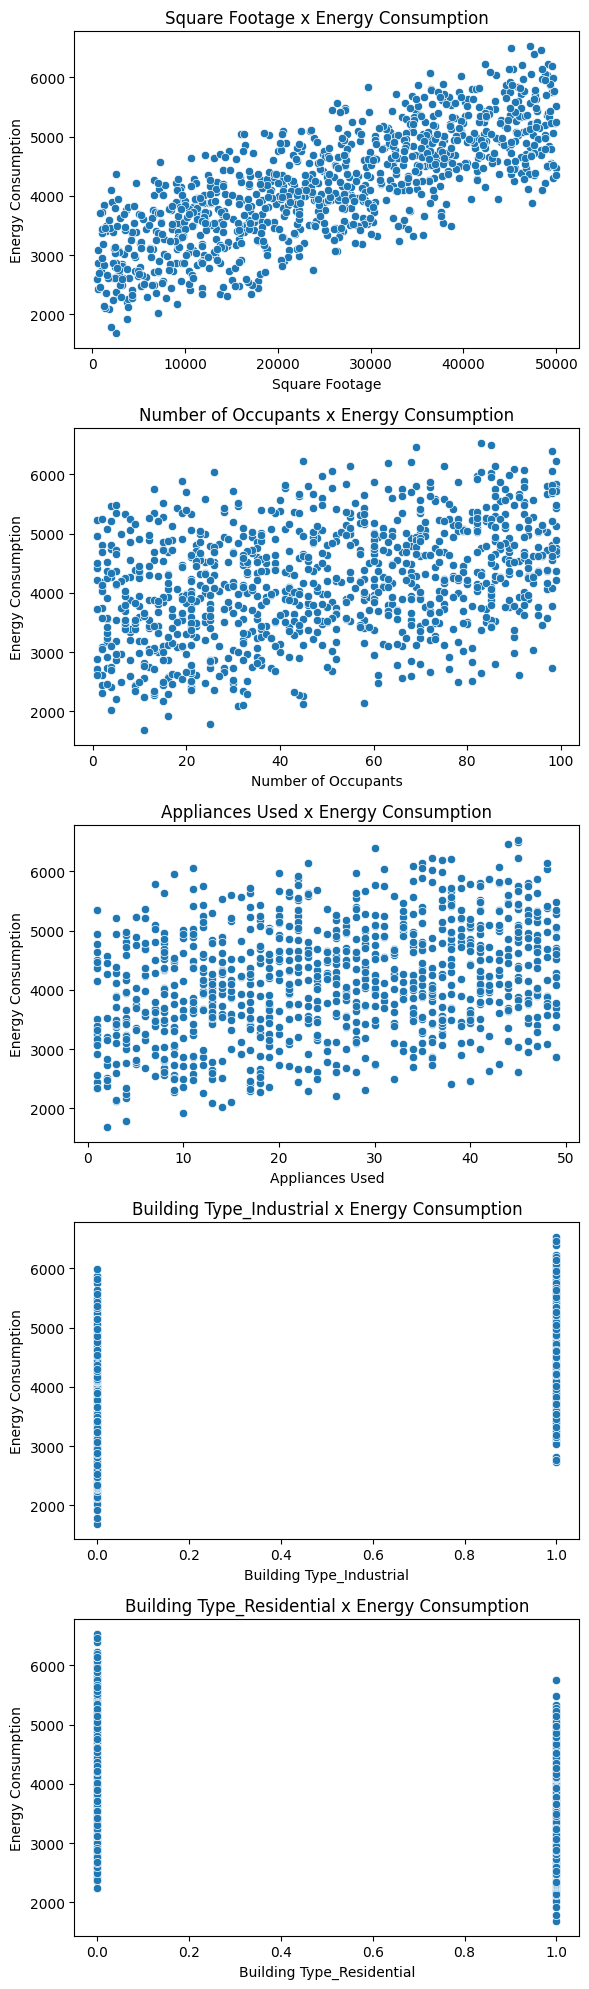

In [55]:
columns_pair = [
    ('Square Footage', 'Energy Consumption'),
    ('Number of Occupants', 'Energy Consumption'),
    ('Appliances Used', 'Energy Consumption'),
    ('Building Type_Industrial', 'Energy Consumption'),
    ('Building Type_Residential', 'Energy Consumption')
]

n_plot = len(columns_pair)

fig, axes = plt.subplots(
    nrows = n_plot,
    ncols = 1,
    figsize = ( 6, 4 * n_plot)
)

for i, pair in enumerate(columns_pair):
    x_col, y_col = pair
    sns.scatterplot(
        x = x_col,
        y = y_col,
        data = train,
        ax = axes[i]
    )

    axes[i].set_title(f'{x_col} x {y_col}')

plt.tight_layout()
plt.show()



In [56]:
form = ('np.log(Q("Energy Consumption")) ~ Q("Square Footage") + Q("Number of Occupants") + Q("Appliances Used") + Q("Building Type_Industrial")')

model = sm.ols(
    formula = form, data = train
)

model = model.fit()

model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                   OLS Regression Results                                  
===========================================================================================
Dep. Variable:     np.log(Q("Energy Consumption"))   R-squared:                       0.921
Model:                                         OLS   Adj. R-squared:                  0.921
Method:                              Least Squares   F-statistic:                     2917.
Date:                             Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                                     17:54:38   Log-Likelihood:                 1288.9
No. Observations:                             1000   AIC:                            -2568.
Df Residuals:                                  995   BIC:                            -2543.
Df Model:                                        4                                         
Covariance Type:                         nonrobust                                         
=================================================================================================
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept                         7.6743      0.007   1130.747      0.000       7.661       7.688
Q("Square Footage")            1.239e-05   1.48e-07     83.665      0.000    1.21e-05    1.27e-05
Q("Number of Occupants")          0.0026   7.29e-05     35.013      0.000       0.002       0.003
Q("Appliances Used")              0.0053      0.000     35.525      0.000       0.005       0.006
Q("Building Type_Industrial")     0.1830      0.005     40.235      0.000       0.174       0.192
==============================================================================
Omnibus:                       49.460   Durbin-Watson:                   1.950
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               56.406
Skew:                          -0.536   Prob(JB):                     5.64e-13
Kurtosis:                       3.451   Cond. No.                     9.48e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 9.48e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

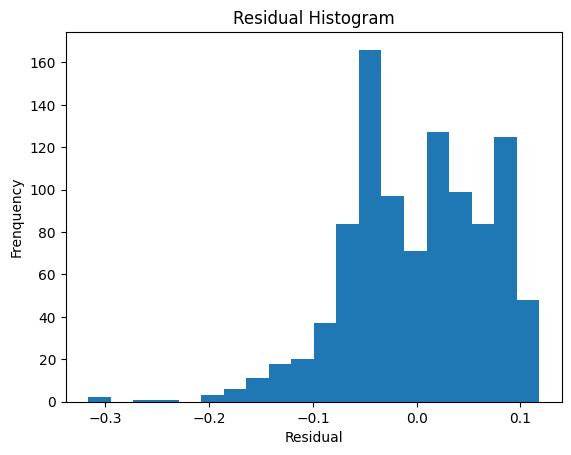

In [57]:
residual = model.resid

plt.hist(residual, bins = 20)
plt.xlabel('Residual')
plt.ylabel('Frenquency')
plt.title('Residual Histogram')
plt.show()

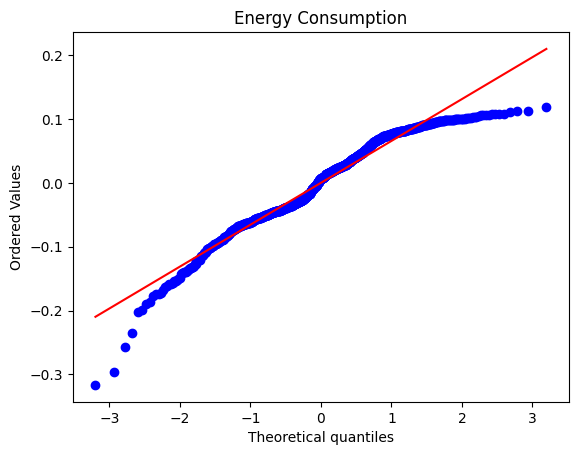

In [58]:
stats.probplot(residual, dist = 'norm', plot = plt)
plt.title('Energy Consumption')
plt.show()

In [59]:
shapiro_wilker_test = stats.shapiro(residual)
print(f'Shapiro Wilk Test \nW: {shapiro_wilker_test[0]} \nP Value: {shapiro_wilker_test[1]}')

Shapiro Wilk Test 
W: 0.962409336247709 
P Value: 2.2548851456276958e-15


In [62]:
prediction = np.exp(model.predict(test))
real = test['Energy Consumption']

error_mediun = np.mean(np.abs(real - prediction))
error_mediun_percent = np.mean(np.abs(real - prediction) / real) * 100
rmse_log = np.sqrt(np.mean((np.log(prediction) - np.log(real)) **2))
r2 = 1 - np.sum((real - prediction) **2) / np.sum((real - real.mean()) **2)

print(f'Erro médio: {error_mediun}')
print(f'Percentual médio de erro: {error_mediun_percent}')
print(f'RMSE (log): {rmse_log}')
print(f'R²: {r2}')

comapration = pd.DataFrame({
    'Real': real,
    'Prediction': prediction
})

comapration['Diference'] = comapration['Real'] - comapration['Prediction']

comapration['Diference (%)'] = ((comapration['Prediction'] - comapration['Real']) / comapration['Real']) * 100

comapration.head()


Erro médio: 190.08578896070642
Percentual médio de erro: 4.907827541613889
RMSE (log): 0.05907951115692277
R²: 0.9295130112040829


,Real,Prediction,Diference,Diference (%)
0,2865.57,3097.439332,-231.869332,8.091561
1,4283.80,3950.601816,333.198184,-7.778099
2,5067.83,4820.523303,247.306697,-4.879933
3,4624.30,4890.892092,-266.592092,5.765026
4,4820.59,5053.739216,-233.149216,4.836529
